<a href="https://colab.research.google.com/github/MD-Zahid-Hasan-Tushar/zahid_H_project4/blob/main/Histogram_Equalization_Techniques_for_Low_Light_Image_Enhancement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from PIL import Image
import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
import keras
from huggingface_hub import from_pretrained_keras

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
high = "/content/drive/MyDrive/CV project/LOLdataset/BrighteningTrain/high"
low = "/content/drive/MyDrive/CV project/LOLdataset/BrighteningTrain/low

SyntaxError: unterminated string literal (detected at line 2) (<ipython-input-5-b0183482781c>, line 2)

In [ ]:
paths = []
for img_path in os.listdir(low):
  paths.append(img_path)

  name = random.choice(paths)

NameError: name 'os' is not defined

In [ ]:
def generate_and_plot(low_img_path, high_img_path):
      low_img = cv2.imread(low_img_path)
      high_img = cv2.imread(high_img_path)


      fig, axes = plt.subplots(1, 2, figsize=(10, 5))


      axes[0].imshow(cv2.cvtColor(low_img, cv2.COLOR_BGR2RGB))
      axes[0].set_title("Low Quality")
      axes[0].axis('off')


      axes[1].imshow(cv2.cvtColor(high_img, cv2.COLOR_BGR2RGB))
      axes[1].set_title("High Quality")
      axes[1].axis('off')

      plt.show()

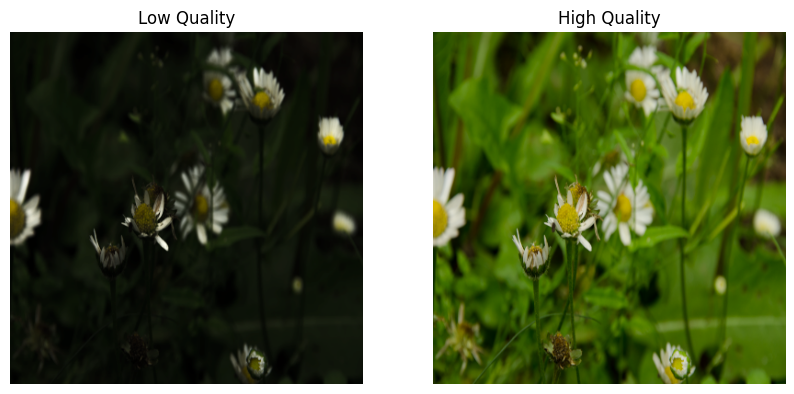

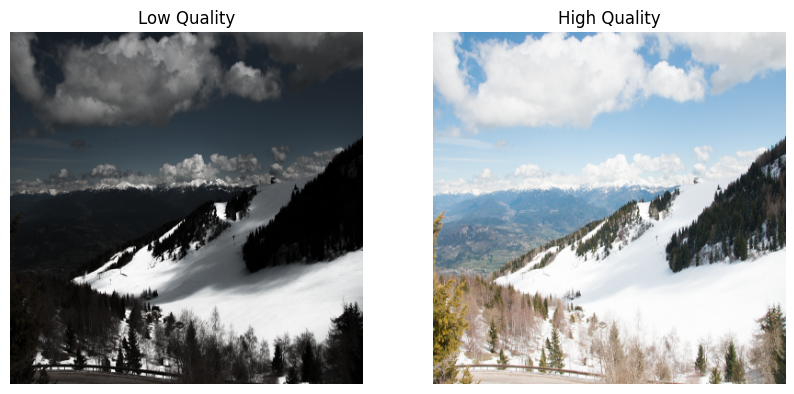

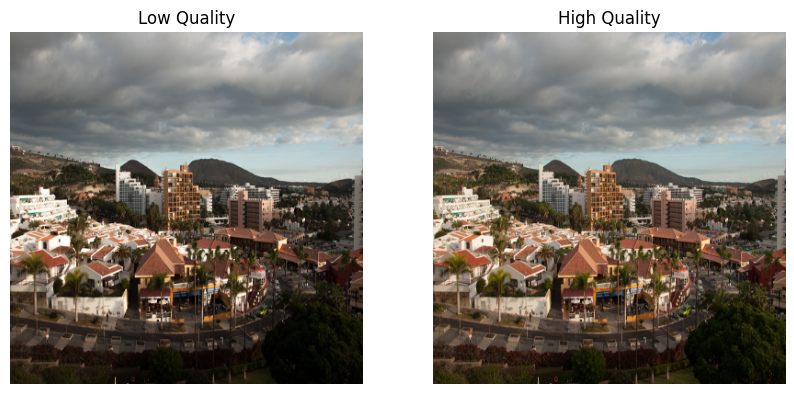

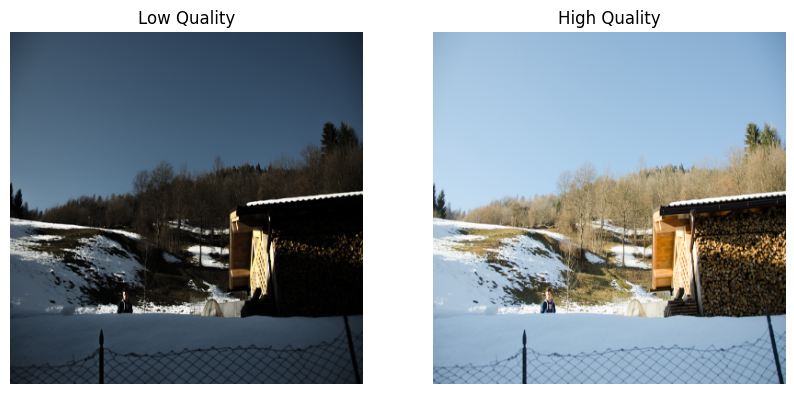

In [ ]:
for _ in range(4):
      img_name = random.choice(paths)
      low_img_path = os.path.join(low, img_name)
      high_img_path = os.path.join(high, img_name)
      generate_and_plot(low_img_path, high_img_path)

In [ ]:
def histogram_equalisation(img_path, show_image = True):
    original_img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    gray_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2GRAY)

    equalized_img = cv2.equalizeHist(gray_img)

    if show_image == True:
       fig, ax = plt.subplots(1, 3, figsize=(10, 10))
       ax[0].imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
       ax[0].set_title("Original Image")
       ax[0].axis('off')

       ax[1].imshow(cv2.cvtColor(gray_img, cv2.COLOR_GRAY2RGB))
       ax[1].set_title("GRAY Image")
       ax[1].axis('off')

       ax[2].imshow(cv2.cvtColor(equalized_img, cv2.COLOR_GRAY2RGB))
       ax[2].set_title("Histogram Equalised Image")
       ax[2].axis('off')

       plt.show()


low_img = os.path.join(low, name)
histogram_equalisation(low_img)






NameError: name 'os' is not defined

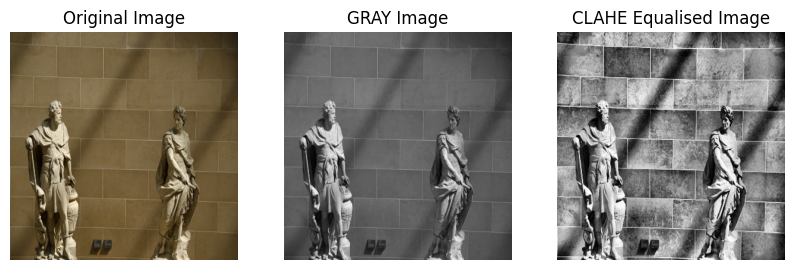

In [ ]:
def clahe_equalisation(img_path, show_image = True):

    original_img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    gray_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2GRAY)

    clahe = cv2.createCLAHE(clipLimit=10.0, tileGridSize=(8,8))
    equalized_img_clahe = clahe.apply(gray_img)

    if show_image == True:
      fig, ax = plt.subplots(1, 3, figsize=(10, 10))
      ax[0].imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
      ax[0].set_title("Original Image")
      ax[0].axis('off')

      ax[1].imshow(cv2.cvtColor(gray_img, cv2.COLOR_GRAY2RGB))
      ax[1].set_title("GRAY Image")
      ax[1].axis('off')

      ax[2].imshow(cv2.cvtColor(equalized_img_clahe, cv2.COLOR_GRAY2RGB))
      ax[2].set_title("CLAHE Equalised Image")
      ax[2].axis('off')

      plt.show()

low_img_clahe = os.path.join(low, name)
clahe_equalisation(low_img_clahe)


In [ ]:
model = from_pretrained_keras("keras-io/lowlight-enhance-mirnet", compile=False)

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/1.67k [00:00<?, ?B/s]

.gitattributes:   0%|          | 0.00/1.25k [00:00<?, ?B/s]

demo.png:   0%|          | 0.00/1.45M [00:00<?, ?B/s]

...

(…)fevents.1645063719.e472ca747184.299.0.v2:   0%|          | 0.00/4.56M [00:00<?, ?B/s]

variables/variables.index:   0%|          | 0.00/219k [00:00<?, ?B/s]

keras_metadata.pb:   0%|          | 0.00/2.19M [00:00<?, ?B/s]

saved_model.pb:   0%|          | 0.00/14.0M [00:00<?, ?B/s]

variables.data-00000-of-00001:   0%|          | 0.00/437M [00:00<?, ?B/s]

1/1 [==============================] - 51s 51s/step


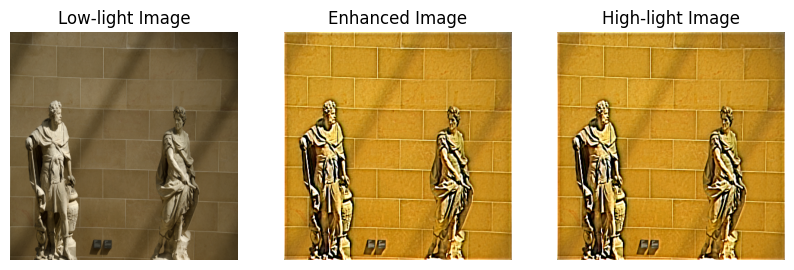

In [ ]:
def mirnet(low_path, high_path):
    low_light_img = Image.open(low_path).convert('RGB')
    high_light_img = Image.open(high_path).convert('RGB')

    image = keras.preprocessing.image.img_to_array(low_light_img)
    image = image.astype('float32') / 255.0
    image = np.expand_dims(image, axis=0)

    output = model.predict(image)
    output_image = output[0] * 255.0
    output_image = np.clip(output_image, 0, 255)
    output_image = output_image.reshape((np.shape(output_image)[0], np.shape(output_image)[1], 3))
    output_image = np.uint8(output_image)

    fig, axes = plt.subplots(1, 3, figsize=(10, 5))
    axes[0].imshow(low_light_img)
    axes[0].set_title('Low-light Image')
    axes[0].axis('off')

    axes[1].imshow(output_image)
    axes[1].set_title('Enhanced Image')
    axes[1].axis('off')

    axes[2].imshow(output_image)
    axes[2].set_title('High-light Image')
    axes[2].axis('off')

    plt.show()

low_img_clahe = os.path.join(low, name)
high_img_clahe = os.path.join(high, name)
mirnet(low_img_clahe, high_img_clahe)

